# 1.  Install these dependencies 
#### Note 
Please create a new Conda environment and use the Conda package manager to install libraries to avoid conflicts. 
We do not emphasize any particular version of the library.


In [ ]:
pip install pandas
pip install spacy
pip install tqdm
pip install swifter
pip install matplotlib
pip install scikit-learn
pip install numpy
pip install sentence-transformers
pip install umap-learn
pip install yake
pip install langchain-community
pip install openpyxl
pip install wordcloud

In [ ]:
!python -m spacy download en_core_web_sm


# 2. Import Libraries

In [25]:
# Standard Library
import os
import re
import os
import numpy as np
# Data Manipulation and Analysis
import pandas as pd
import numpy as np


# Natural Language Processing
import spacy
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModel

# Clustering and Similarity
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

# Keyword Extraction
from yake import KeywordExtractor

# Visualization
import matplotlib.pyplot as plt
import umap
import seaborn as sns
from scipy.spatial import ConvexHull

# Progress Bar
from tqdm import tqdm

# Parallel Processing
import swifter

# Language Model Integration
from langchain_community.llms import Ollama
from sklearn.cluster import KMeans
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
import inflect  
import spacy
import inflect
from yake import KeywordExtractor
import torch
nlp = spacy.load("en_core_web_sm")
inflect_engine = inflect.engine()
from langchain_community.llms import Ollama

# 3. Import Data and Files

Google_Drive_Link: 

In [2]:
os.chdir("C:\\Users\\Saddam_Hussain\\FinalCodeAndDataFiles")


## Loading All Data Files

# All the Data Files Can Be downloaded : 
https://drive.google.com/drive/folders/1iDmNsb1wcDv50SgCWitsvEwMqD1OxlxA?usp=drive_link
## Please Download these Files and verify 
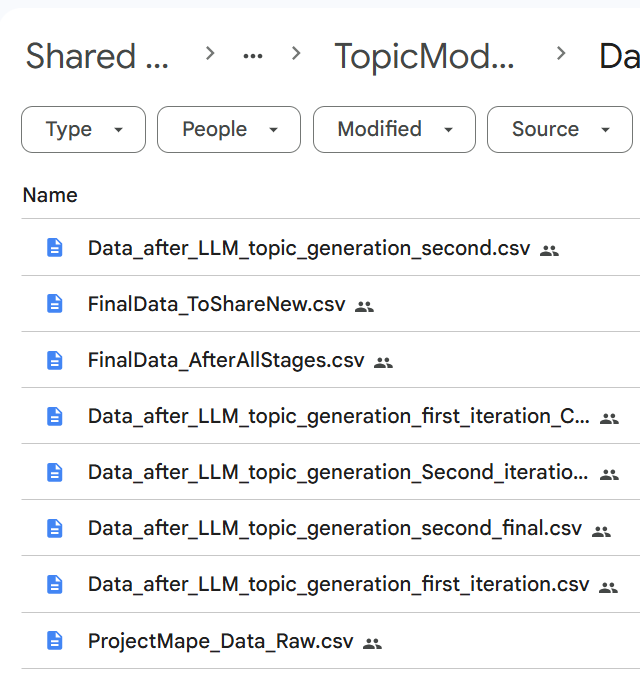

In [3]:
def load_data_files():
    df = pd.read_csv("Data_Files\\ProjectMape_Data_Raw.csv")
    print("ProjectMape_Data_Raw.csv loaded successfully.")
    print(df.shape)
    print(df.info())

    Data_after_LLM_topic_generation_first_iteration = pd.read_csv("Data_Files\\Data_after_LLM_topic_generation_first_iteration.csv")
    print("Data_after_LLM_topic_generation_first_iteration.csv loaded successfully.")
    print(Data_after_LLM_topic_generation_first_iteration.shape)
    print(Data_after_LLM_topic_generation_first_iteration.info())

    Data_after_LLM_topic_generation_second = pd.read_csv("Data_Files\\Data_after_LLM_topic_generation_second.csv")
    print("Data_after_LLM_topic_generation_second.csv loaded successfully.")
    print(Data_after_LLM_topic_generation_second.shape)
    print(Data_after_LLM_topic_generation_second.info())

    Data_after_LLM_topic_generation_Second_iteration = pd.read_csv("Data_Files\\Data_after_LLM_topic_generation_second_final.csv")
    print("Data_after_LLM_topic_generation_second_final.csv loaded successfully.")
    print(Data_after_LLM_topic_generation_Second_iteration.shape)
    print(Data_after_LLM_topic_generation_Second_iteration.info())

    Data_after_LLM_topic_generation_first_iteration_CosineSim = pd.read_csv("Data_Files\\Data_after_LLM_topic_generation_first_iteration_CosineSim.csv")
    print("Data_after_LLM_topic_generation_first_iteration_CosineSim.csv loaded successfully.")
    print(Data_after_LLM_topic_generation_first_iteration_CosineSim.shape)
    print(Data_after_LLM_topic_generation_first_iteration_CosineSim.info())

    Data_after_LLM_topic_generation_Second_iteration_CosineSim = pd.read_csv("Data_Files\\Data_after_LLM_topic_generation_Second_iteration_CosineSim.csv")
    print("Data_after_LLM_topic_generation_Second_iteration_CosineSim.csv loaded successfully.")
    print(Data_after_LLM_topic_generation_Second_iteration_CosineSim.shape)
    print(Data_after_LLM_topic_generation_Second_iteration_CosineSim.info())

    FinalData = pd.read_csv("Data_Files\\FinalData_ToShareNew.csv")
    print("FinalData_ToShareNew.csv loaded successfully.")
    print(FinalData.shape)
    print(FinalData.info())

    return (df, 
            Data_after_LLM_topic_generation_first_iteration, 
            Data_after_LLM_topic_generation_second, 
            Data_after_LLM_topic_generation_Second_iteration, 
            Data_after_LLM_topic_generation_first_iteration_CosineSim, 
            Data_after_LLM_topic_generation_Second_iteration_CosineSim, 
            FinalData)

(df, 
 Data_after_LLM_topic_generation_first_iteration, 
 Data_after_LLM_topic_generation_second, 
 Data_after_LLM_topic_generation_Second_iteration, 
 Data_after_LLM_topic_generation_first_iteration_CosineSim, 
 Data_after_LLM_topic_generation_Second_iteration_CosineSim, 
 FinalData) = load_data_files()

ProjectMape_Data_Raw.csv loaded successfully.
(168045, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168045 entries, 0 to 168044
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   reference_code  168045 non-null  object
 1   doc_url         168045 non-null  object
 2   doc_year        168045 non-null  object
 3   doc_source      168045 non-null  object
 4   doc_text_port   168045 non-null  object
dtypes: object(5)
memory usage: 6.4+ MB
None
Data_after_LLM_topic_generation_first_iteration.csv loaded successfully.
(168045, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168045 entries, 0 to 168044
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   reference_code       168045 non-null  object
 1   doc_url              168045 non-null  object
 2   doc_year             168045 non-null  object
 3   doc_source           1

## Loading All Embedding FIles and other related

#### All the Embedding Files Can Be downloaded : 
https://drive.google.com/drive/folders/1jAk8lg47qJdbK7BeI_ICUZa7Y0ZAWo6w?usp=drive_link
#### Please Download these Files and verify 
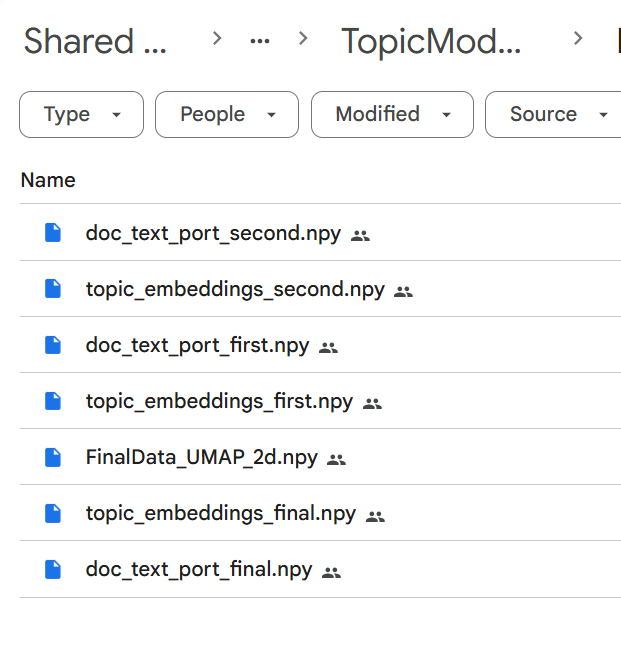

In [4]:
def load_embeddings():
    primary_path = "C:\\Users\\Saddam_Hussain\\FinalCodeAndDataFiles"
    embeddings_path = os.path.join(primary_path, "Embedding_Files")

    os.chdir(primary_path)

    topic_embeddings_path = os.path.join(embeddings_path, "doc_text_port_first.npy")
    print(f"Loading: {topic_embeddings_path}")
    topic_embeddings = np.load(topic_embeddings_path)

    doc_text_port_emb_path = os.path.join(embeddings_path, "topic_embeddings_first.npy")
    print(f"Loading: {doc_text_port_emb_path}")
    doc_text_port_emb = np.load(doc_text_port_emb_path)

    topic_embeddings_path_second = os.path.join(embeddings_path, "doc_text_port_second.npy")
    print(f"Loading: {topic_embeddings_path_second}")
    topic_embeddings_second = np.load(topic_embeddings_path_second)

    doc_text_embeddings_path_second = os.path.join(embeddings_path, "topic_embeddings_second.npy")
    print(f"Loading: {doc_text_embeddings_path_second}")
    doc_text_embeddings_second = np.load(doc_text_embeddings_path_second)

    doc_text_port_embeddings_final_path = os.path.join(embeddings_path, "doc_text_port_final.npy")
    print(f"Loading: {doc_text_port_embeddings_final_path}")
    doc_text_port_embeddings_final = np.load(doc_text_port_embeddings_final_path)

    llm_topics_embeddings_final_path = os.path.join(embeddings_path, "topic_embeddings_final.npy")
    print(f"Loading: {llm_topics_embeddings_final_path}")
    llm_topics_embeddings_final = np.load(llm_topics_embeddings_final_path)

    embeddings_2d_path = os.path.join(primary_path, "finaldata_embeddings_2d.npy")
    print(f"Loading: {embeddings_2d_path}")
    embeddings_2d = np.load(embeddings_2d_path)

    return topic_embeddings, doc_text_port_emb, topic_embeddings_second, doc_text_embeddings_second, doc_text_port_embeddings_final, llm_topics_embeddings_final, embeddings_2d

topic_embeddings_first, doc_text_port_emb_first,topic_embeddings_second, doc_text_embeddings_second,doc_text_port_embeddings_final, llm_topics_embeddings_final, embeddings_2d = load_embeddings()


Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\doc_text_port_first.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\topic_embeddings_first.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\doc_text_port_second.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\topic_embeddings_second.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\doc_text_port_final.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\Embedding_Files\topic_embeddings_final.npy
Loading: C:\Users\Saddam_Hussain\FinalCodeAndDataFiles\finaldata_embeddings_2d.npy


In [ ]:
#df = pd.read_csv("ProjectMape_Data_Raw.csv")

In [5]:
df.head(3)

,reference_code,doc_url,doc_year,doc_source,doc_text_port
0,PT/AHU/CU/017-001/0044/10239,https://digitarq.ahu.arquivos.pt/details?id=11...,1738-01,RIODEJANEIRO-CA,"REQUERIMENTO de Manuel da Silva, sargento supr..."
1,PT/AHU/CU/062/0003/00071,https://digitarq.ahu.arquivos.pt/details?id=14...,1733-12,MACAU,Representação dos oficiais da Câmara de Macau ...
2,PT/AHU/CU/146/0043/02940,https://digitarq.ahu.arquivos.pt/details?id=11...,1828-09,MADEIRA,"REQUERIMENTO de Matilde Augusta de Oliveira, e..."


# 4. Topic Generation Using LLM
<div style="text-align: center;">
    <h1 style="color: #007BFF;">⬇️🌟 <strong>Start of Stage-1</strong> 🚀⬇️</h1>
</div>


# 🌟 Flow Chart of Topic Generation 🌟

## 📋 Flowchart Steps

### 1️⃣ Load Dataset (`load_dataset_with_progress`)
- 🔍 **Check if the column `'LLM Suggested Topic'` exists** in the dataset.
- 🆕 If not, create the column and **start fresh**.
- ▶️ If it exists, **resume processing** from the last unprocessed row.

### 2️⃣ Load Language Model (`load_llm`)
- 🛠️ **Initialize and load the LLM** (Language Model) **Ollama** with the latest version for topic generation.

### 3️⃣ Extract Topic from Letter (`extract_topic_from_letter`)
- ✏️ **Use the LLM** to generate a concise topic for a given letter.
- ⚡ Ignore specific details like **dates, names, or locations**, focusing only on the **main subject**.

### 4️⃣ Process Dataset and Save Progress (`process_and_save`)
- 🔄 **Iterate over the dataset**, starting from the first unprocessed row.
- 📝 For each row:
  - Extract the **letter text**.
  - Generate a **topic** using the LLM.
  - Update the dataset with the **generated topic**.
- 💾 **Save progress** after every 5 rows to avoid data loss.
- ✅ Save the **final processed dataset** after completing all rows.

### 5️⃣ Main Function (`main`)
- 🚀 **Execute the entire workflow**:
  - Load the dataset.
  - Process all unprocessed rows and **generate topics** using the LLM.
  - Save the **final dataset** with topics for future use.

---

## 🎯 Flowchart (Visual Representation)

```plaintext
🎬 Start
  ⬇️
📂 Load Dataset
  ⬇️
❓ Check if 'LLM Suggested Topic' column exists
  ├── ✔️ Yes: Resume processing
  └── ❌ No: Create column, start fresh
  ⬇️
🤖 Load LLM
  ⬇️
🔄 Iterate over unprocessed rows
  ⬇️
For each row:
  - ✏️ Extract letter text
  - 🛠️ Generate topic with LLM
  - 💾 Save progress every 5 rows
  ⬇️
📂 Save final dataset
  ⬇️
🏁 End


# Diagram of Generating Topics Using LLM

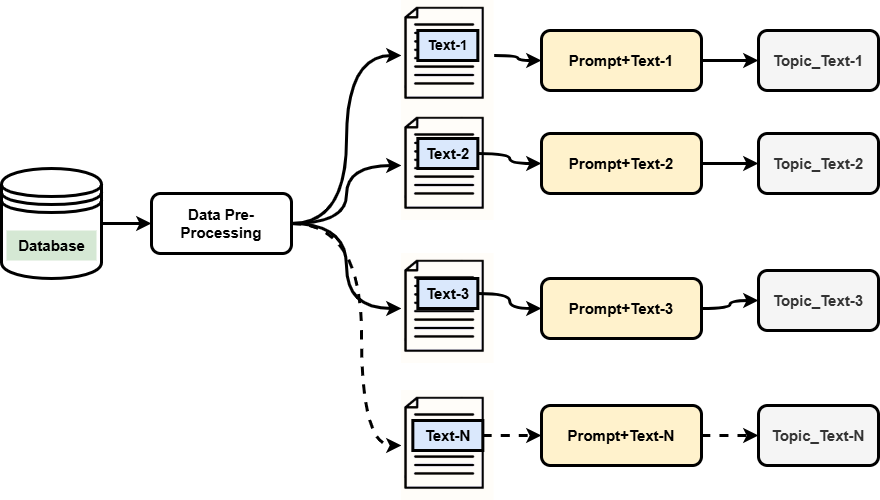

In [ ]:
def load_dataset_with_progress():
    if 'LLM Suggested Topic' not in df.columns:
        df['LLM Suggested Topic'] = None 
        print("Column 'LLM Suggested Topic' created. Starting fresh.")
    else:
        print("Column 'LLM Suggested Topic' found. Continuing from the last processed row.")

    return df

def load_llm():
    llm = Ollama(model="llama3.2:latest")  
    return llm

def extract_topic_from_letter(llm, text):
    prompt = (
        f"Given the following historical letter, generate a concise topic for cataloging purposes. "
        f"Ignore any references to dates, people’s names, or locations. "
        f"Focus only on the main topic of the letter. Keep it short and focused on the subject discussed:\n\n"
        f"{text}\n\n"
        f"Main Topic:"
    )
    topic = llm.predict(prompt).strip()
    return topic

def process_and_save(df, file_path="letters_with_topics.csv"):
    llm = load_llm()

    start_index = df[df['LLM Suggested Topic'].isna()].index.min()
    if pd.isna(start_index):
        print("All rows are already processed.")
        return df

    save_interval = 50  
    for i in range(start_index, len(df)):
        row = df.iloc[i]
        if pd.isna(row['LLM Suggested Topic']): 
            letter_text = row['doc_text_port']
            topic = extract_topic_from_letter(llm, letter_text)
            df.at[i, 'LLM Suggested Topic'] = topic

            print(f"Processing Letter {i+1}:")
            print(f"Text: {letter_text}")
            print(f"Generated Topic: {topic}\n")

            if (i + 1) % save_interval == 0:
                df.to_csv(file_path, index=False)
                print(f"Progress saved after {i+1} rows to '{file_path}'.")

    df.to_csv(file_path, index=False)
    print(f"Final progress saved to '{file_path}'.")

    return df

def main():
    df = load_dataset_with_progress()
    df_with_topics = process_and_save(df)
    df_with_topics.to_csv("Data_after_LLM_topic_generation_first_iteration.csv", index=False)
    print("Final dataset saved as 'Data_after_LLM_topic_generation_first_iteration.csv'.")

main()

#### Data After Topic Generation Via LLM

In [ ]:
#Data_after_LLM_topic_generation_first_iteration= pd.read_csv("Data_after_LLM_topic_generation_first_iteration.csv")


In [7]:
Data_after_LLM_topic_generation_first_iteration.head(3)

,reference_code,doc_url,doc_year,doc_source,doc_text_port,LLM Suggested Topic
0,PT/AHU/CU/017-001/0044/10239,https://digitarq.ahu.arquivos.pt/details?id=11...,1738-01,RIODEJANEIRO-CA,"REQUERIMENTO de Manuel da Silva, sargento supr...",Request for Military Promotion
1,PT/AHU/CU/062/0003/00071,https://digitarq.ahu.arquivos.pt/details?id=14...,1733-12,MACAU,Representação dos oficiais da Câmara de Macau ...,request for local ouidore appointment
2,PT/AHU/CU/146/0043/02940,https://digitarq.ahu.arquivos.pt/details?id=11...,1828-09,MADEIRA,"REQUERIMENTO de Matilde Augusta de Oliveira, e...",Travel and Documentation Requests


<div style="text-align: center;">
    <h1 style="color: #28A745;">⬆️🎯 <strong>End of Stage-1</strong> 🎉⬆️</h1>
</div>


# 5. Topic Validation : LLM Generated topic against given Input Text

<div style="text-align: center;">
    <h1 style="color: #007BFF;">⬇️🌟 <strong>Start of Stage-2</strong> 🚀⬇️</h1>
</div>


# ✨ Validation Workflow ✨

## 📋 Overview
Building on the first stage, where initial topics were generated and validated:
1. **Initial Topics**: Generated using the **Primary LLM** in the first stage.
2. **Threshold Set**: Based on **2 standard deviations** of cosine similarity distribution.
3. **Second Iteration for Refinement**: This stage focuses on rows with **low cosine similarity scores** (below the threshold).
4. **Validation**: Embeddings and cosine similarities are recomputed to confirm improvements in topic alignment.

---

## 📋 Steps and Workflow

### 1️⃣ Load Dataset with Topics
- 📂 **Load the dataset** containing generated topics from the first stage.
- 🔍 **Check if the column `'LLM Suggested Topic Refine'` exists**:
  - 🆕 If not, create the column and **start fresh refinement**.
  - ▶️ If it exists, **resume processing** from the last unprocessed row.

---

### 2️⃣ Load Language Models
- 🤖 Load two models:
  - **Primary LLM**: Used to regenerate topics for low similarity rows.
  - **Governing LLM**: Used to refine topics with stricter adherence to the letter's context.

---

### 3️⃣ Refine Topics for Low Similarity Rows
- 🔄 Iterate over rows with **cosine similarity below the threshold** (e.g., 0.48).
- For each low similarity row:
  - ✏️ **Generate a new topic** using the **Primary LLM**.
  - 🔧 **Refine the topic** using the **Governing LLM** to ensure accuracy and context adherence.
  - 📝 Update the dataset with the **refined topic**.

---

### 4️⃣ Compute Embeddings and Cosine Similarities
- 🧠 Recompute embeddings for:
  - 📄 Document texts.
  - 🏷️ Refined topics.
- 📊 Recalculate **cosine similarities** between document embeddings and refined topic embeddings.

---

### 5️⃣ Validation and Visualization
- 📈 **Visualize the new cosine similarity distribution**:
  - Compare it with the threshold (e.g., **0.48**).
  - Check if refined topics improve alignment with document texts.
- ✅ Confirm that the refined topics bring more rows above the threshold.
- 🔎 Identify any remaining low similarity rows for further inspection.

---

## 🎯 Flowchart (Visual Representation)

```plaintext
🎬 Start
  ⬇️
📂 Load Dataset with Topics
  ⬇️
❓ Check if 'LLM Suggested Topic Refine' column exists
  ├── ✔️ Yes: Resume refinement
  └── ❌ No: Create column, start fresh
  ⬇️
🔍 Identify Rows Below Threshold
  ⬇️
🔄 Iterate Over Low Similarity Rows
  - ✏️ Generate topic with Primary LLM
  - 🔧 Refine topic with Governing LLM
  - 📝 Update dataset
  ⬇️
🧠 Compute Embeddings
  - 📄 Document embeddings
  - 🏷️ Refined topic embeddings
  ⬇️
📊 Validate Cosine Similarities
  - Plot similarity distribution
  - Compare against threshold
  - Identify any remaining low-scoring rows
  ⬇️
🏁 End


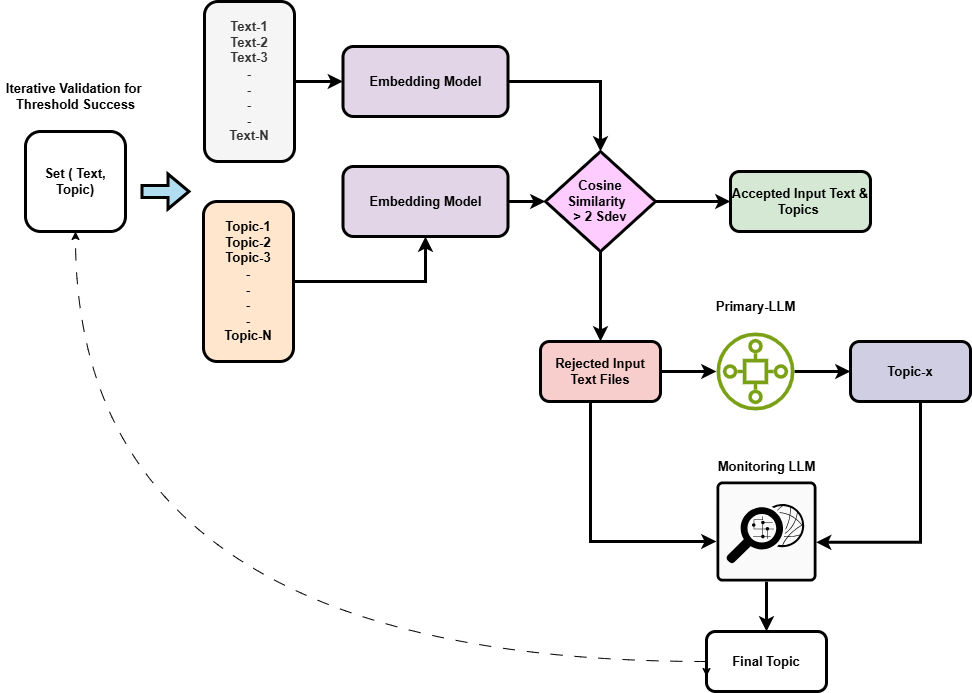

### Embedding Generation And Validation
This code computes embeddings for document texts and their corresponding LLM-generated topics using the **"Alibaba-NLP/gte-multilingual-base"** model. 

- **Model Initialization**: Loads the tokenizer and model for generating multilingual embeddings.
- **Embedding Computation**: Uses `compute_embeddings_with_progress` to process each text, extract embeddings, and store them.
- **Device Compatibility**: Automatically runs on GPU if available, otherwise defaults to CPU.
- **Saving Outputs**: Saves the computed embeddings for both document texts (`doc_text_port`) and LLM topics (`llm_topics`) as `.npy` files for later use.


#### Embedding Generation Start

In [ ]:
model_name = "Alibaba-NLP/gte-multilingual-base"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(model_name, trust_remote_code=True)


def compute_embeddings_with_progress(texts, tokenizer, model, device='cpu'):
    model = model.to(device)
    embeddings = []
    
    for text in tqdm(texts, desc="Computing Embeddings"):
        inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
        inputs = {key: val.to(device) for key, val in inputs.items()}
        
        with torch.no_grad():
            outputs = model(**inputs)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
    
    return np.vstack(embeddings)


device = 'cuda' if torch.cuda.is_available() else 'cpu'


In [ ]:
doc_text_port = Data_after_LLM_topic_generation_first_iteration['doc_text_port'].tolist()
llm_topics = Data_after_LLM_topic_generation_first_iteration['LLM Suggested Topic'].tolist()

doc_text_port_embeddings_first = compute_embeddings_with_progress(doc_text_port, tokenizer, model, device)
topics_embeddings_first = compute_embeddings_with_progress(llm_topics,tokenizer, model, device)


np.save("doc_text_port_first.npy", doc_text_port_embeddings_first)

np.save("topic_embeddings_first.npy", topics_embeddings_first)

#### Embedding Generation Ended 

### Compute Cosine Similarity

This code calculates and visualizes the cosine similarity between document embeddings and topic embeddings to evaluate topic alignment:

- **Load Embeddings**: 
  - Loads the saved embeddings for document texts (`doc_text_port_first`) and LLM-generated topics (`topic_embeddings_first`) from `.npy` files.
  - Ensures embeddings are reshaped correctly for processing.

- **Convert to Tensors**: 
  - Converts embeddings into PyTorch tensors for cosine similarity calculations.
  - Runs on GPU if available, otherwise defaults to CPU.

- **Cosine Similarity**: 
  - Uses `cosine_similarity_torch_rowwise` to calculate cosine similarity scores between the document and topic embeddings.

- **Statistical Analysis**:
  - Computes **mean**, **standard deviation**, and identifies **minimum** and **maximum similarity scores**.

- **Visualization**:
  - Plots a histogram of cosine similarities using Matplotlib and Seaborn:
    - Vertical lines highlight:
      - **Mean** (red).
      - **±1 and ±2 standard deviations** (green and purple).
    - Aims to analyze topic alignment distribution.



In [ ]:
# topic_embeddings_path = "doc_text_port_first.npy"
# doc_text_port_emb_path = "topic_embeddings_first.npy"

# topic_embeddings_first = np.load(topic_embeddings_path) 
# doc_text_port_emb_first = np.load(doc_text_port_emb_path) 

Topic Embeddings Shape is :  (168045, 768)
Document Text Embeddings Shape is :  (168045, 768)


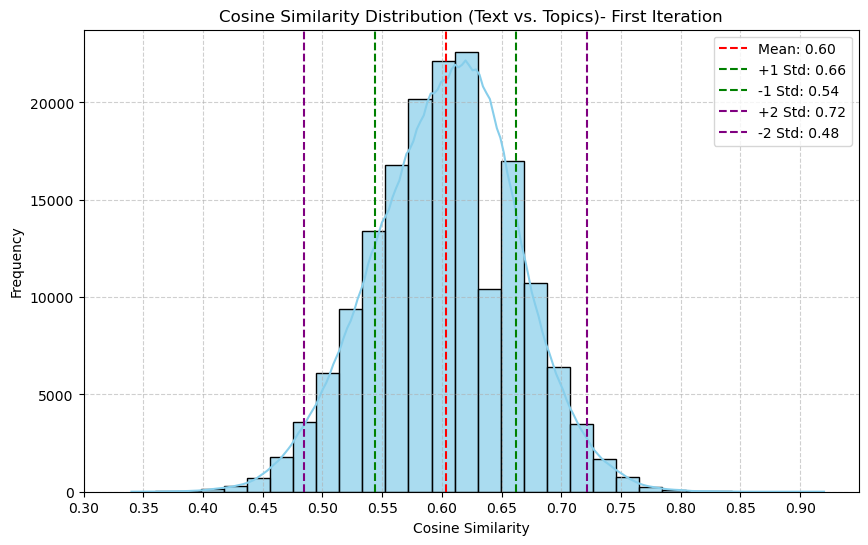

Mean Cosine Similarity: 0.6031
Standard Deviation: 0.0593
Min Similarity: 0.3400
Max Similarity: 0.9200


In [8]:
print("Topic Embeddings Shape is : ",topic_embeddings_first.shape )
print("Document Text Embeddings Shape is : ",doc_text_port_emb_first.shape )
if len(topic_embeddings_first.shape) == 1:
    topic_embeddings_first = topic_embeddings_first.reshape(1, -1)
if len(doc_text_port_emb_first.shape) == 1:
    doc_text_port_emb_first = doc_text_port_emb_first.reshape(1, -1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
topic_embeddings_first = torch.tensor(topic_embeddings_first, dtype=torch.float32, device=device)
doc_text_port_emb_first = torch.tensor(doc_text_port_emb_first, dtype=torch.float32, device=device)


def cosine_similarity_torch_rowwise(embeddings1, embeddings2):
    return torch.nn.functional.cosine_similarity(embeddings1, embeddings2, dim=1)

cosine_similarities = cosine_similarity_torch_rowwise(doc_text_port_emb_first, topic_embeddings_first)

cosine_similarities = cosine_similarities.cpu().numpy()
cosine_similarities = np.round(cosine_similarities, decimals=2)

mean_similarity = np.mean(cosine_similarities)
std_similarity = np.std(cosine_similarities)

x_ticks = np.arange(0.3, 0.95, 0.05)

plt.figure(figsize=(10, 6))
sns.histplot(cosine_similarities, bins=30, kde=True, color='skyblue', edgecolor='black', alpha=0.7)

plt.axvline(mean_similarity, color='red', linestyle='--', label=f'Mean: {mean_similarity:.2f}')
plt.axvline(mean_similarity + std_similarity, color='green', linestyle='--', label=f'+1 Std: {mean_similarity + std_similarity:.2f}')
plt.axvline(mean_similarity - std_similarity, color='green', linestyle='--', label=f'-1 Std: {mean_similarity - std_similarity:.2f}')
plt.axvline(mean_similarity + 2 * std_similarity, color='purple', linestyle='--', label=f'+2 Std: {mean_similarity + 2 * std_similarity:.2f}')
plt.axvline(mean_similarity - 2 * std_similarity, color='purple', linestyle='--', label=f'-2 Std: {mean_similarity - 2 * std_similarity:.2f}')

plt.title('Cosine Similarity Distribution (Text vs. Topics)- First Iteration')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.xticks(x_ticks)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("LLM_Topic_Cosine_Similarity_Diagram_First_After_LLM.png", dpi=500, bbox_inches='tight')

plt.show()

print(f"Mean Cosine Similarity: {mean_similarity:.4f}")
print(f"Standard Deviation: {std_similarity:.4f}")
print(f"Min Similarity: {np.min(cosine_similarities):.4f}")
print(f"Max Similarity: {np.max(cosine_similarities):.4f}")



### Filter rows with cosine similarity scores below the **2-sigma threshold (0.48)**.


In [ ]:
# In this case it is 0.48
Data_after_LLM_topic_generation_first_iteration["Cosine_Sim"] = pd.Series(cosine_similarities)
Data_after_LLM_topic_generation_second = Data_after_LLM_topic_generation_first_iteration[ Data_after_LLM_topic_generation_first_iteration["Cosine_Sim"]<0.48]
Data_after_LLM_topic_generation_second.to_csv("Data_after_LLM_topic_generation_second.csv", index=False, encoding='utf-8-sig')

###  Topic Refinement using Primary LLM & Monitoring LLM

#### **Purpose**:
- Importing the dataset that has low scores
- Refine topics for these rows using a **two-stage LLM process** (Primary LLM and Governing LLM).


---

#### **Key Steps**:

1. **Filter Low Similarity Rows**:
   - Identify rows with cosine similarity scores below **0.48** and save them for refinement.

2. **Load Dataset**:
   - Load the filtered dataset and add a new column (`LLM Suggested Topic Refine`) for refined topics.

3. **Generate and Refine Topics**:
   - Use the **Primary LLM** to generate a new topic.
   - Use the **Governing LLM** to refine the topic for better context adherence.

4. **Save Progress**:
   - Save the dataset after every 5 rows to prevent data loss.

5. **Final Save**:
   - Save the fully refined dataset as `"Data_after_LLM_topic_generation_second_final.csv"`.

---

#### **Summary**:
This code iteratively processes rows with low cosine similarity scores, generating and refining topics to improve topic alignment. It ensures progress is saved regularly and final results are stored for further analysis.


In [ ]:
#Data_after_LLM_topic_generation_second = pd.read_csv("Data_after_LLM_topic_generation_second.csv")


In [9]:
Data_after_LLM_topic_generation_second .head(3)

,reference_code,doc_url,doc_year,doc_source,doc_text_port,LLM Suggested Topic,Cosine_Sim
0,PT/AHU/CU/005-001/0019/03583,https://digitarq.ahu.arquivos.pt/details?id=13...,1758-09,BAHIA-CA,CARTA PARTICULAR de Luiz da Fonseca Ribeiro a ...,Disputes in Military Governance,0.43
1,PT/AHU/CU/017/0191/13751,https://digitarq.ahu.arquivos.pt/details?id=13...,1801-03,RIODEJANEIRO,"OFÍCIO do [vice-rei do Estado do Brasil], cond...",Trade and Economic Exchange,0.44
2,PT/AHU/CU/005/0041/03685,https://digitarq.ahu.arquivos.pt/details?id=12...,1732-02,BAHIA,CONSULTA [do Conselho Ultramarino] sobre devas...,Governance and Administrative Oversight,0.46


In [ ]:

def load_dataset_with_progress(file_path="Data_after_LLM_topic_generation_second.csv"):
    df = pd.read_csv(file_path)
    if 'LLM Suggested Topic Refine' not in df.columns:
        df['LLM Suggested Topic Refine'] = None
    
    print(f"Starting fresh with the dataset. Loaded '{file_path}'.")
    return df

def load_llm():
    primary_llm = Ollama(model="llama3.2:latest")  
    governing_llm = Ollama(model="llama3.2:latest") 
    return primary_llm, governing_llm

def extract_topic_from_letter(primary_llm, text):
    prompt = (
        f"Given the following historical letter, generate a concise topic for cataloging purposes. "
        f"Ignore any references to dates, people’s names, or locations. "
        f"Focus only on the main topic of the letter. Keep it short and focused on the subject discussed:\n\n"
        f"{text}\n\n"
        f"Main Topic:"
    )
    topic = primary_llm.predict(prompt).strip()
    return topic

def refine_topic_with_governing_llm(governing_llm, topic, context):
    prompt = (
        f"The following topic was generated by a primary language model from a historical letter. "
        f"Your job is to refine the Original Topic from Primary LLM, ensuring it strictly adheres to the provided context. "
        f"Final Refined Topic should follow these guidelines: "
        f"Ignore any references to dates, people’s names, or locations. "
        f"Focus only on the main topic of the letter. Keep it short and focused on the subject discussed:\n\n"
        f"Original Topic from Primary LLM: {topic}\n\n"
        f"Context (Historical Letter): {context}\n\n"
        f"Refined Topic:"
        f"Final Response Should Include Only Refined topic without any additional details or commentary other than topic"
    )
    refined_topic = governing_llm.predict(prompt).strip()
    return refined_topic

from tqdm import tqdm  

def process_and_save(df, file_path="Data_after_LLM_topic_generation_second_refinedtopic.csv"):
    primary_llm, governing_llm = load_llm()

    save_interval = 5  
    counter = 0

    for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing Rows"):
        if pd.isna(row['LLM Suggested Topic Refine']):  
            letter_text = row['doc_text_port']          
            topic = extract_topic_from_letter(primary_llm, letter_text)
            print("Topic Generated by Primary LLM:", topic)
            df.at[i, 'LLM Suggested Topic Refine'] = topic  

            refined_topic = refine_topic_with_governing_llm(governing_llm, topic, letter_text)
            print("Topic Refined by Governing LLM:", refined_topic)
            df.at[i, 'LLM Suggested Topic Refine'] = refined_topic  

            counter += 1
            if counter % save_interval == 0:
                df.to_csv(file_path, index=False)
                print(f"Progress saved after {counter} rows to '{file_path}'.")

    df.to_csv(file_path, index=False)
    print(f"Final progress saved to '{file_path}'.")

    return df

def main():
    file_path = "Data_Files\\Data_after_LLM_topic_generation_second.csv"
    df = load_dataset_with_progress(file_path)

    df_with_topics = process_and_save(df)

    df_with_topics.to_csv("Data_after_LLM_topic_generation_second_final.csv", index=False)
    print("Final dataset saved as 'data_less_than_threshold_final.csv'.")

main()


In [ ]:
#Data_after_LLM_topic_generation_Second_iteration  = pd.read_csv("Data_after_LLM_topic_generation_second_final.csv")

In [12]:
Data_after_LLM_topic_generation_Second_iteration.head(3)

,Unnamed: 0,reference_code,doc_url,doc_year,doc_source,doc_text_port,LLM Suggested Topic,LLM Suggested Topic Refine
0,154,PT/AHU/CU/011/0136/10533,https://digitarq.ahu.arquivos.pt/details?id=12...,1791-08,MINASGERAIS,CERTIDÃO como teor das sentenças dadas nos aut...,Dispute Resolution and Governance,Certification of court rulings in Morro do Bru...
1,325,PT/AHU/CU/016/0006/00396,https://digitarq.ahu.arquivos.pt/details?id=13...,1760-02,PIAUÍ,"OFÍCIO do [desembargador], Francisco Marcelino...",Governance of Royal Tithes,Official correspondence about the 1759 tax auc...
2,941,PT/AHU/CU/003/0026/02198,https://digitarq.ahu.arquivos.pt/details?id=12...,1787-04,BRASIL-GERAL,LISTA dos teares que há na vila de São João d’...,Governance and Administrative Challenges,List of looms in São João d’El Rei under Capta...


In [ ]:
doc_text_port_second = Data_after_LLM_topic_generation_Second_iteration['doc_text_port'].tolist()
llm_topics_second = Data_after_LLM_topic_generation_Second_iteration['LLM Suggested Topic Refine'].tolist()

doc_text_port_embeddings_second = compute_embeddings_with_progress(doc_text_port_second , tokenizer, model, device)
llm_topics_embeddings_second = compute_embeddings_with_progress(llm_topics_second ,tokenizer, model, device)


np.save("doc_text_port_second.npy", doc_text_port_embeddings_second)

np.save("topic_embeddings_second.npy", llm_topics_embeddings_second)

Topic Embeddings Shape is: (2943, 768)
Document Text Embeddings Shape is: (2943, 768)


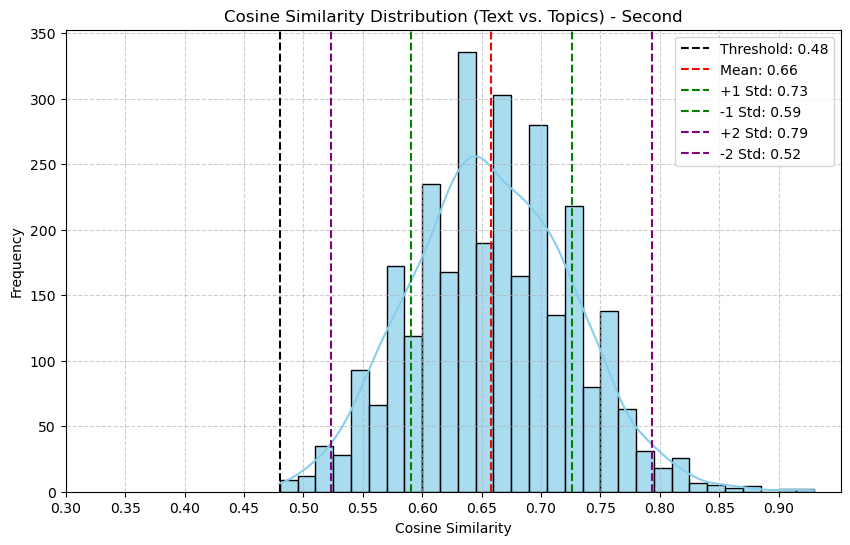

Mean Cosine Similarity (Second): 0.6582
Standard Deviation (Second): 0.0675
Min Similarity (Second): 0.4800
Max Similarity (Second): 0.9300


In [13]:
# topic_embeddings_path_second = "doc_text_port_second.npy"
# doc_text_embeddings_path_second = "topic_embeddings_second.npy"

# topic_embeddings_second = np.load(topic_embeddings_path_second)
# doc_text_embeddings_second = np.load(doc_text_embeddings_path_second)

print("Topic Embeddings Shape is:", topic_embeddings_second.shape)
print("Document Text Embeddings Shape is:", doc_text_embeddings_second.shape)

if len(topic_embeddings_second.shape) == 1:
    topic_embeddings_second = topic_embeddings_second.reshape(1, -1)
if len(doc_text_embeddings_second.shape) == 1:
    doc_text_embeddings_second = doc_text_embeddings_second.reshape(1, -1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
topic_embeddings_second = torch.tensor(topic_embeddings_second, dtype=torch.float32, device=device)
doc_text_embeddings_second = torch.tensor(doc_text_embeddings_second, dtype=torch.float32, device=device)

def cosine_similarity_torch_rowwise(embeddings1, embeddings2):
    return torch.nn.functional.cosine_similarity(embeddings1, embeddings2, dim=1)

cosine_similarities_second = cosine_similarity_torch_rowwise(doc_text_embeddings_second, topic_embeddings_second)

cosine_similarities_second = cosine_similarities_second.cpu().numpy()
cosine_similarities_second = np.round(cosine_similarities_second, decimals=2)

mean_similarity_second = np.mean(cosine_similarities_second)
std_similarity_second = np.std(cosine_similarities_second)

x_ticks_second = np.arange(0.3, 0.95, 0.05)

plt.figure(figsize=(10, 6))
sns.histplot(cosine_similarities_second, bins=30, kde=True, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(0.48, color='black', linestyle='--', label='Threshold: 0.48')

plt.axvline(mean_similarity_second, color='red', linestyle='--', label=f'Mean: {mean_similarity_second:.2f}')
plt.axvline(mean_similarity_second + std_similarity_second, color='green', linestyle='--', label=f'+1 Std: {mean_similarity_second + std_similarity_second:.2f}')
plt.axvline(mean_similarity_second - std_similarity_second, color='green', linestyle='--', label=f'-1 Std: {mean_similarity_second - std_similarity_second:.2f}')
plt.axvline(mean_similarity_second + 2 * std_similarity_second, color='purple', linestyle='--', label=f'+2 Std: {mean_similarity_second + 2 * std_similarity_second:.2f}')
plt.axvline(mean_similarity_second - 2 * std_similarity_second, color='purple', linestyle='--', label=f'-2 Std: {mean_similarity_second - 2 * std_similarity_second:.2f}')

plt.title('Cosine Similarity Distribution (Text vs. Topics) - Second')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.xticks(x_ticks_second)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("LLM_Topic_Cosine_Similarity_Diagram_Second.png", dpi=500, bbox_inches='tight')
plt.show()

print(f"Mean Cosine Similarity (Second): {mean_similarity_second:.4f}")
print(f"Standard Deviation (Second): {std_similarity_second:.4f}")
print(f"Min Similarity (Second): {np.min(cosine_similarities_second):.4f}")
print(f"Max Similarity (Second): {np.max(cosine_similarities_second):.4f}")


## It can be observed that now all data points achieve higher threshold i.e greater than 0.48

In [ ]:
Data_after_LLM_topic_generation_Second_iteration["Cosine_Sim"] = cosine_similarities_second

In [ ]:
Data_after_LLM_topic_generation_Second_iteration = Data_after_LLM_topic_generation_Second_iteration[[ 'reference_code', 'doc_url', 'doc_year', 'doc_source',
       'doc_text_port', 'LLM Suggested Topic Refine', 'Cosine_Sim']]
Data_after_LLM_topic_generation_Second_iteration.rename(columns={'LLM Suggested Topic Refine': 'LLM Suggested Topic' }, inplace=True)


In [ ]:
Data_after_LLM_topic_generation_first_iteration[['reference_code', 'doc_url', 'doc_year', 'doc_source', 'doc_text_port',
       'LLM Suggested Topic', 'Cosine_Sim']].to_csv("Data_after_LLM_topic_generation_first_iteration_CosineSim.csv", index=False, encoding='utf-8-sig')

Data_after_LLM_topic_generation_Second_iteration[['reference_code', 'doc_url', 'doc_year', 'doc_source', 'doc_text_port',
       'LLM Suggested Topic', 'Cosine_Sim']].to_csv("Data_after_LLM_topic_generation_Second_iteration_CosineSim.csv", index=False, encoding='utf-8-sig')

In [ ]:
Data_after_LLM_topic_generation_first_iteration_CosineSim = pd.read_csv("Data_after_LLM_topic_generation_first_iteration_CosineSim.csv")
Data_after_LLM_topic_generation_Second_iteration_CosineSim  = pd.read_csv("Data_after_LLM_topic_generation_Second_iteration_CosineSim.csv")


In [14]:
Data_after_LLM_topic_generation_first_iteration_CosineSim.head(3)

,reference_code,doc_url,doc_year,doc_source,doc_text_port,LLM Suggested Topic,Cosine_Sim
0,PT/AHU/CU/017-001/0044/10239,https://digitarq.ahu.arquivos.pt/details?id=11...,1738-01,RIODEJANEIRO-CA,"REQUERIMENTO de Manuel da Silva, sargento supr...",Request for Military Promotion,0.71
1,PT/AHU/CU/062/0003/00071,https://digitarq.ahu.arquivos.pt/details?id=14...,1733-12,MACAU,Representação dos oficiais da Câmara de Macau ...,request for local ouidore appointment,0.58
2,PT/AHU/CU/146/0043/02940,https://digitarq.ahu.arquivos.pt/details?id=11...,1828-09,MADEIRA,"REQUERIMENTO de Matilde Augusta de Oliveira, e...",Travel and Documentation Requests,0.60


In [15]:
Data_after_LLM_topic_generation_Second_iteration_CosineSim.head(3)

,reference_code,doc_url,doc_year,doc_source,doc_text_port,LLM Suggested Topic,Cosine_Sim
0,PT/AHU/CU/011/0136/10533,https://digitarq.ahu.arquivos.pt/details?id=12...,1791-08,MINASGERAIS,CERTIDÃO como teor das sentenças dadas nos aut...,Certification of court rulings in Morro do Bru...,0.67
1,PT/AHU/CU/016/0006/00396,https://digitarq.ahu.arquivos.pt/details?id=13...,1760-02,PIAUÍ,"OFÍCIO do [desembargador], Francisco Marcelino...",Official correspondence about the 1759 tax auc...,0.75
2,PT/AHU/CU/003/0026/02198,https://digitarq.ahu.arquivos.pt/details?id=12...,1787-04,BRASIL-GERAL,LISTA dos teares que há na vila de São João d’...,List of looms in São João d’El Rei under Capta...,0.79


In [ ]:
Data_after_LLM_topic_generation_first_iteration.columns

In [ ]:
Data_after_LLM_topic_generation_first_iteration_gt_thresh = Data_after_LLM_topic_generation_first_iteration_CosineSim[Data_after_LLM_topic_generation_Second_iteration_CosineSim ["Cosine_Sim"]>=0.48]

In [ ]:
Data_after_LLM_topic_generation_Second_iteration_CosineSim  = Data_after_LLM_topic_generation_Second_iteration_CosineSim .reset_index(drop=True)
Data_after_LLM_topic_generation_first_iteration_gt_thresh = Data_after_LLM_topic_generation_first_iteration_gt_thresh.reset_index(drop=True)

In [ ]:
FinalData = pd.concat(
    [Data_after_LLM_topic_generation_Second_iteration_CosineSim, 
    Data_after_LLM_topic_generation_first_iteration_gt_thresh],
    ignore_index=True
)


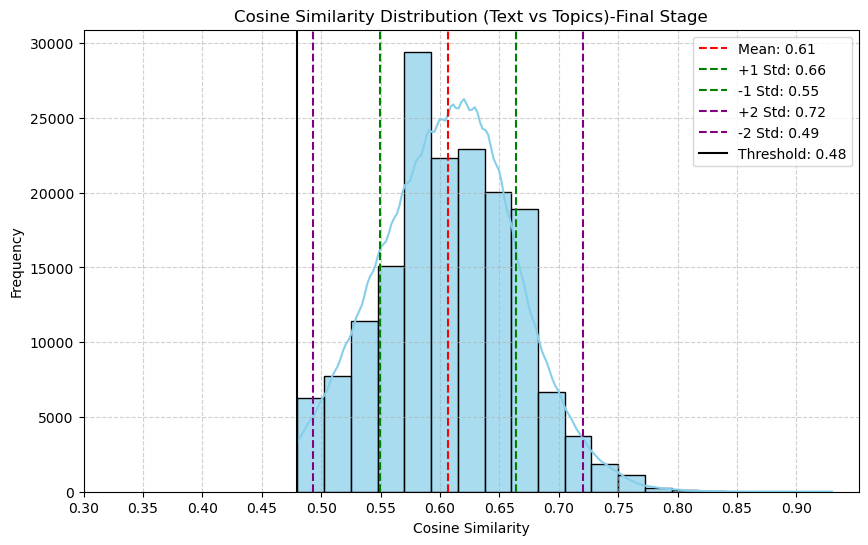

Mean Cosine Similarity: 0.6067
Standard Deviation: 0.0569
Min Similarity: 0.4800
Max Similarity: 0.9300


In [16]:

cosine_similarities = FinalData['Cosine_Sim'].values

cosine_similarities = np.round(cosine_similarities, decimals=2)

mean_similarity = np.mean(cosine_similarities)
std_similarity = np.std(cosine_similarities)

x_ticks = np.arange(0.3, 0.95, 0.05)

plt.figure(figsize=(10, 6))
sns.histplot(cosine_similarities, bins=20, kde=True, color='skyblue', edgecolor='black', alpha=0.7)

plt.axvline(mean_similarity, color='red', linestyle='--', label=f'Mean: {mean_similarity:.2f}')
plt.axvline(mean_similarity + std_similarity, color='green', linestyle='--', label=f'+1 Std: {mean_similarity + std_similarity:.2f}')
plt.axvline(mean_similarity - std_similarity, color='green', linestyle='--', label=f'-1 Std: {mean_similarity - std_similarity:.2f}')
plt.axvline(mean_similarity + 2 * std_similarity, color='purple', linestyle='--', label=f'+2 Std: {mean_similarity + 2 * std_similarity:.2f}')
plt.axvline(mean_similarity - 2 * std_similarity, color='purple', linestyle='--', label=f'-2 Std: {mean_similarity - 2 * std_similarity:.2f}')

plt.axvline(0.48, color='black', linestyle='-', label='Threshold: 0.48')

plt.title('Cosine Similarity Distribution (Text vs Topics)-Final Stage')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.xticks(x_ticks)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Save the plot as an image
#plt.savefig("FinalStage-Cosine Similarity Distribution (Text vs Topics).png", dpi=500, bbox_inches='tight')

# Display the plot
plt.show()

# Print statistics
print(f"Mean Cosine Similarity: {mean_similarity:.4f}")
print(f"Standard Deviation: {std_similarity:.4f}")
print(f"Min Similarity: {np.min(cosine_similarities):.4f}")
print(f"Max Similarity: {np.max(cosine_similarities):.4f}")


In [ ]:
#FinalData.to_csv("FinalData_AfterAllStages.csv", index=False, encoding='utf-8-sig')

<div style="text-align: center;">
    <h1 style="color: #28A745;">⬆️🎯 <strong>End of Stage-2</strong> 🎉⬆️</h1>
</div>


<div style="text-align: center;">
    <h1 style="color: #007BFF;">⬇️🌟 <strong>Start of Stage-3</strong> 🚀⬇️</h1>
</div>


## 🔍 Explanation of Code: Final Embeddings, Clustering, and Topic Categorization

## Key Steps:

### 1️⃣ **Load and Compute Final Embeddings**
- **Purpose**: Combine document and topic embeddings for clustering.
- **Actions**:
  - Load the final dataset (`FinalData`).
  - Compute embeddings for `doc_text_port` and `LLM Suggested Topic`.
  - Combine embeddings into a single matrix and save them for reuse.

---

### 2️⃣ **Dimensionality Reduction**
- **Purpose**: Reduce combined embeddings for efficient clustering and visualization.
- **Actions**:
  - Use **UMAP** to reduce embeddings to:
    - **2 dimensions** for clustering.
    - **2 dimensions** for visualization.

---

### 3️⃣ **Clustering**
- **Purpose**: Group documents into clusters based on reduced embeddings.
- **Actions**:
  - Use **KMeans** with 8 clusters chosen based on Elbow Algorithm and optimized parameters.
  - Assign each document a cluster label.

---
## Higher Level Grouping 
### 4️⃣ **Keyword Extraction per Cluster**
- **Purpose**: Extract keywords for each cluster to identify key themes.
- **Actions**:
  - Preprocess text (remove stop words, lemmatize, singularize).
  - Use **YAKE** to extract top keywords for each cluster.

---

### 5️⃣ **Generate Cluster Topics Using LLM**
- **Purpose**: Summarize cluster themes using keywords.
- **Actions**:
  - Use an LLM (`llama3.2`) to generate a concise topic for each cluster based on extracted keywords.

---

### 6️⃣ **Assign Topics to Clusters**
- **Purpose**: Add generated topics to the dataset.
- **Actions**:
  - Map cluster labels to their corresponding topics.
  - Assign topics to all rows in the dataset.

---

### 7️⃣ **Collapse Topics into Broad Categories**
- **Purpose**: Group cluster topics into broader categories for easier interpretation.
- **Actions**:
  - Use the LLM to map each cluster topic to categories such as **Governance**, **Military**, **Trade**, etc.
  - Add the broad category column to the dataset.

---

## 🚀 Results:
1. Final dataset includes:
   - Cluster labels (`Cluster_Label`).
   - Cluster topics (`Cluster_Topic`).
   - Broad categories (`Broad_Category`).
2. Data is now ready for interpretation and further analysis.

---



In [ ]:
#FinalData = pd.read_csv("FinalData_AfterAllStages.csv")


In [ ]:
doc_text_port_final = FinalData['doc_text_port'].tolist()
llm_topics_final = FinalData['LLM Suggested Topic'].tolist()

doc_text_port_embeddings_final = compute_embeddings_with_progress(doc_text_port_final , tokenizer, model, device)
llm_topics_embeddings_final = compute_embeddings_with_progress(llm_topics_final ,tokenizer, model, device)


np.save("doc_text_port_final.npy", doc_text_port_embeddings_final)

np.save("topic_embeddings_final.npy", llm_topics_embeddings_final)

In [ ]:
# doc_text_port_embeddings_final = np.load("doc_text_port_final.npy")
# llm_topics_embeddings_final = np.load("topic_embeddings_final.npy")

In [ ]:
combined_embeddings = np.hstack((doc_text_port_embeddings_final, llm_topics_embeddings_final))
embeddings_2d = fit_umap_with_progress(combined_embeddings, n_components=2, desc="Reducing to 2D")



In [ ]:
np.save("finaldata_embeddings_2d.npy", embeddings_2d)


In [ ]:
#embeddings_2d = np.load("C:\\Users\Saddam_Hussain\\FinalCodeAndDataFiles\\finaldata_embeddings_2d.npy")

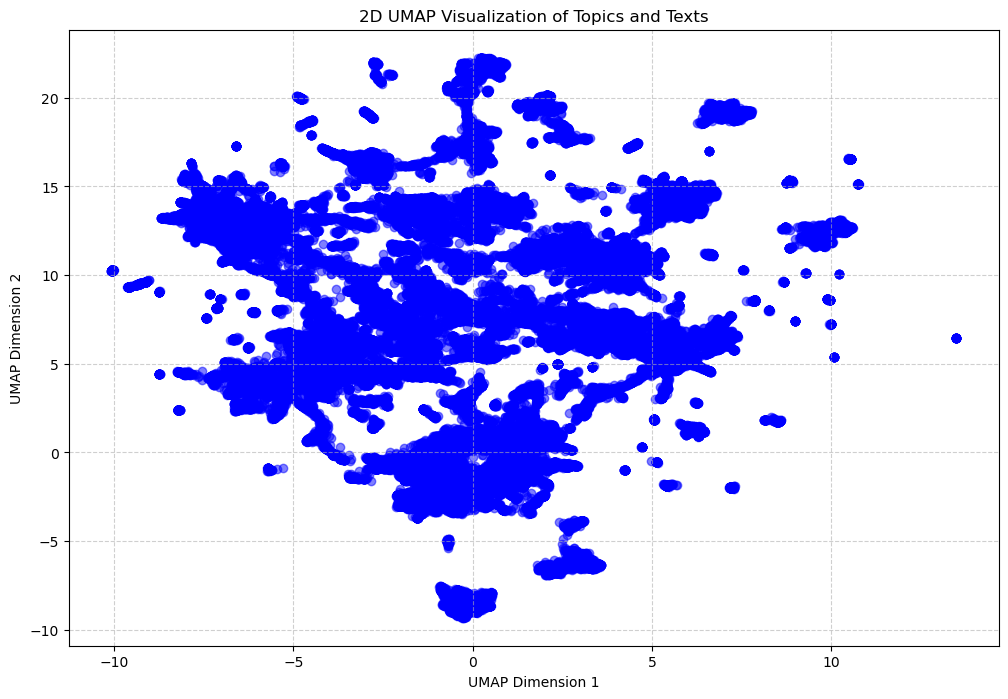

In [17]:
plt.figure(figsize=(12, 8))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], color='blue', alpha=0.5)
plt.title('2D UMAP Visualization of Topics and Texts')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.grid(True, linestyle='--', alpha=0.6)
#plt.savefig("uFinalData_umap2d.png")
plt.show()

### kMeans clustering 

In [ ]:
inertia = []
cluster_range = range(2, 20)

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(embeddings_2d)
    inertia.append(kmeans.inertia_)




In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, inertia, marker='o')
plt.axvline(x=8, color='red', linestyle='--', label='Chosen: 8 Clusters')
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia (SSE)")
plt.xticks(cluster_range)
plt.grid(True)
plt.legend()

plt.savefig("elbow_method_500dpi.png", dpi=500, bbox_inches='tight')
plt.show()


In [19]:
kmeans = KMeans(n_clusters=8,
                n_init=200,
                max_iter=1000,
                algorithm="elkan",
                random_state=42)
kmeans_labels_8 = kmeans.fit_predict(embeddings_2d)

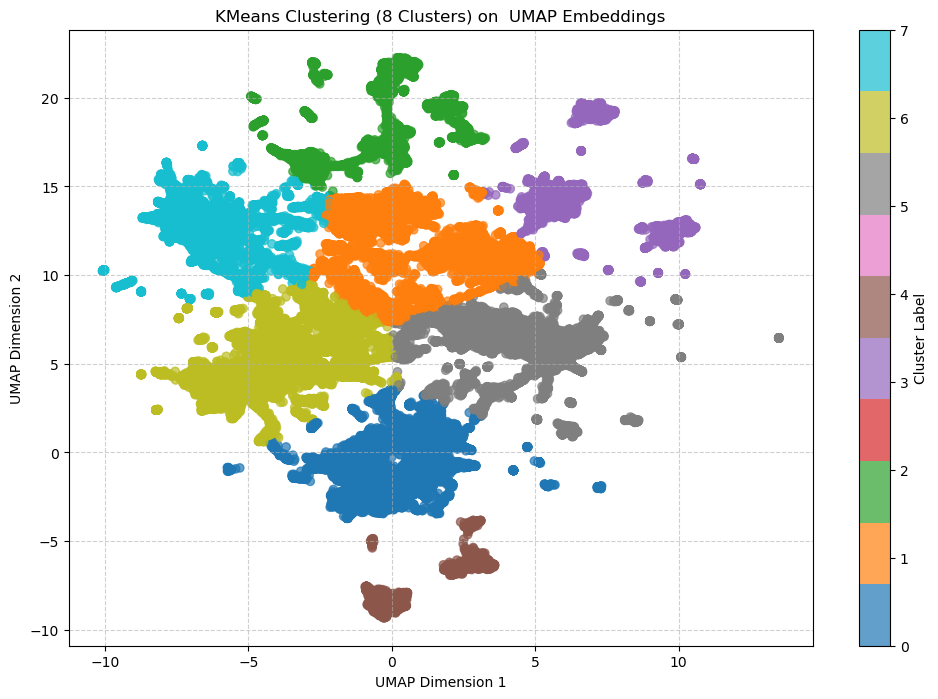

In [20]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=kmeans_labels_8,  
    cmap="tab10",  
    alpha=0.7
)
plt.colorbar(scatter, label="Cluster Label")
plt.title("KMeans Clustering (8 Clusters) on  UMAP Embeddings")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.grid(True, linestyle="--", alpha=0.6)

#plt.savefig("kmeans_8_clusters_visualization_50d_500dpi.png", dpi=500)
plt.show()


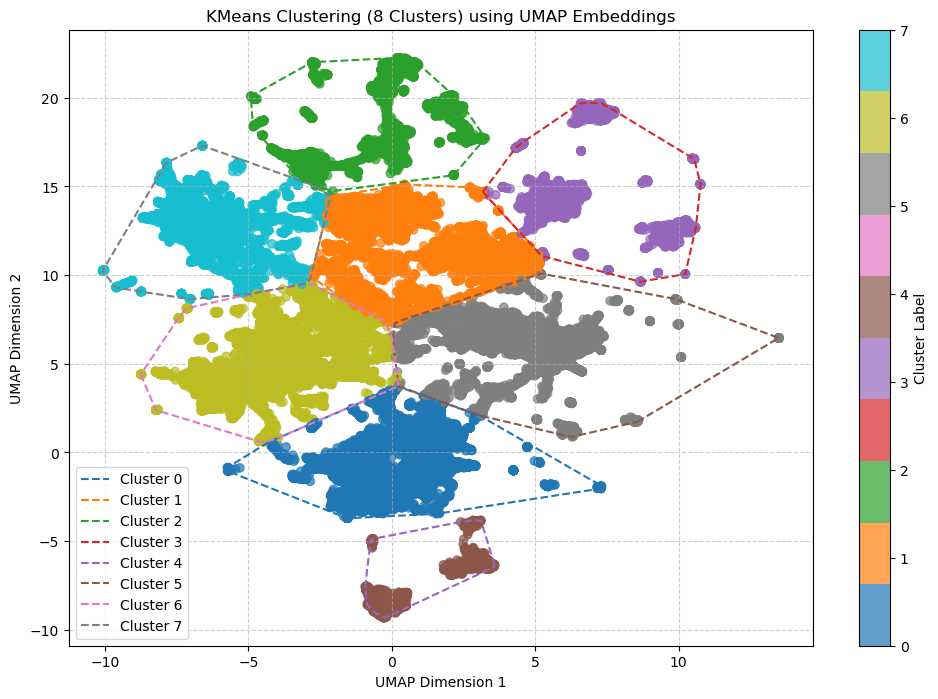

In [33]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=kmeans_labels_8,  
    cmap="tab10", 
    alpha=0.7
)

unique_labels = np.unique(kmeans_labels_8)
for label in unique_labels:
    points = embeddings_2d[kmeans_labels_8 == label]
    
    if len(points) >= 3:  
        hull = ConvexHull(points)
        hull_points = points[hull.vertices]
        plt.plot(
            np.append(hull_points[:, 0], hull_points[0, 0]),
            np.append(hull_points[:, 1], hull_points[0, 1]),
            linestyle="--",
            linewidth=1.5,
            label=f"Cluster {label}"
        )

plt.colorbar(scatter,
             label="Cluster Label")
plt.title("KMeans Clustering (8 Clusters) using UMAP Embeddings")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.grid(True, 
         linestyle="--", 
         alpha=0.6)
plt.legend()  

plt.savefig("kmeans_8_clusters_visualization.png", dpi=500)

plt.show()


## Generating Higher Level Groupings 

### Going First Higher Level i.e choosing 100 clusters 

In [ ]:
kmeans = KMeans(n_clusters=100,
                random_state=42)
kmeans_labels_2d = kmeans.fit_predict(embeddings_2d)
kmeans_labels_2d = kmeans.labels_
FinalData["Cluster_Label"] = kmeans_labels_2d



In [ ]:
def preprocess_text(text):
    doc = nlp(text.lower())  
    tokens = []
    for token in doc:
        if not token.is_stop and not token.is_punct and token.is_alpha:
            lemma = token.lemma_
            singular = inflect_engine.singular_noun(lemma)
            tokens.append(singular if singular else lemma)
    return " ".join(tokens)

def extract_keywords_per_cluster(df, cluster_labels, num_clusters=100, top_n=5):

    df['Cluster_Label'] = cluster_labels
    keyword_extractor = KeywordExtractor(lan="en", n=2, top=top_n)
    cluster_keywords = {}

    for cluster in range(num_clusters):
        cluster_texts = df[df['Cluster_Label'] == cluster]['LLM Suggested Topic'].tolist()
        preprocessed_texts = [preprocess_text(text) for text in cluster_texts]
        combined_text = " ".join(preprocessed_texts)
        keywords = keyword_extractor.extract_keywords(combined_text)
        cluster_keywords[cluster] = [kw[0] for kw in keywords]
        print(f"Cluster {cluster}: {cluster_keywords[cluster]}")

    return cluster_keywords

cluster_keywords_yake = extract_keywords_per_cluster(
    FinalData,
    kmeans_labels_2d,
    num_clusters=100,
    top_n=100
)


In [ ]:

def generate_cluster_topics_with_llm(cluster_keywords, llm_model="llama3.2:latest"):

    llm = Ollama(model=llm_model)
    cluster_topics = {}
    
    for cluster, keywords in cluster_keywords.items():
        prompt = (
            f"The data is from the Portuguese Empire colonial dataset. "
            f"Given these keywords for Cluster {cluster}: {', '.join(keywords)}, "
            f"Dont Add Explanations or any commentary. Just Produce the One Topic That Caputres the overall theme of all keywords."
            f"generate a concise and meaningful label for this cluster."
        )
        response = llm.predict(prompt).strip()
        cluster_topics[cluster] = response
        print(f"Cluster {cluster} Topic: {response}")
    
    return cluster_topics

cluster_topics = generate_cluster_topics_with_llm(cluster_keywords_yake)
def assign_topics_to_clusters(df, cluster_topics):
    df['Cluster_Label_Topic'] = df['Cluster_Label'].map(cluster_topics)
    return df

FinalData = assign_topics_to_clusters(FinalData, cluster_topics)
def collapse_topics_to_broad_categories_with_llm(df, llm_model="llama3.2:latest"):
    llm = Ollama(model=llm_model)
    unique_topics = df['Cluster_Label_Topic'].unique().tolist()

    broad_categories = {}
    for topic in unique_topics:
        prompt = (
            f"The data is from the Portuguese Empire colonial dataset. "
            f"Given this topic: '{topic}', group it into a broad category that captures the overall theme, "
            f"such as Governance, Military, Trade, Property, Finance, Legal, Religion, Travel, Welfare, or Titles. "
            f"Only provide the category name without explanation."
        )
        response = llm.predict(prompt).strip()
        broad_categories[topic] = response
        print(f"Topic '{topic}' mapped to: {response}")

    df['Broad_Category'] = df['Cluster_Label_Topic'].map(broad_categories)
    return df

FinalData = collapse_topics_to_broad_categories_with_llm(FinalData)



In [ ]:
#FinalData.to_csv("FinalData_ToShareNew.csv", index=False,encoding='utf-8-sig')

In [ ]:
# FinalData = pd.read_csv("FinalData_ToShareNew.csv")
# FinalData.info()

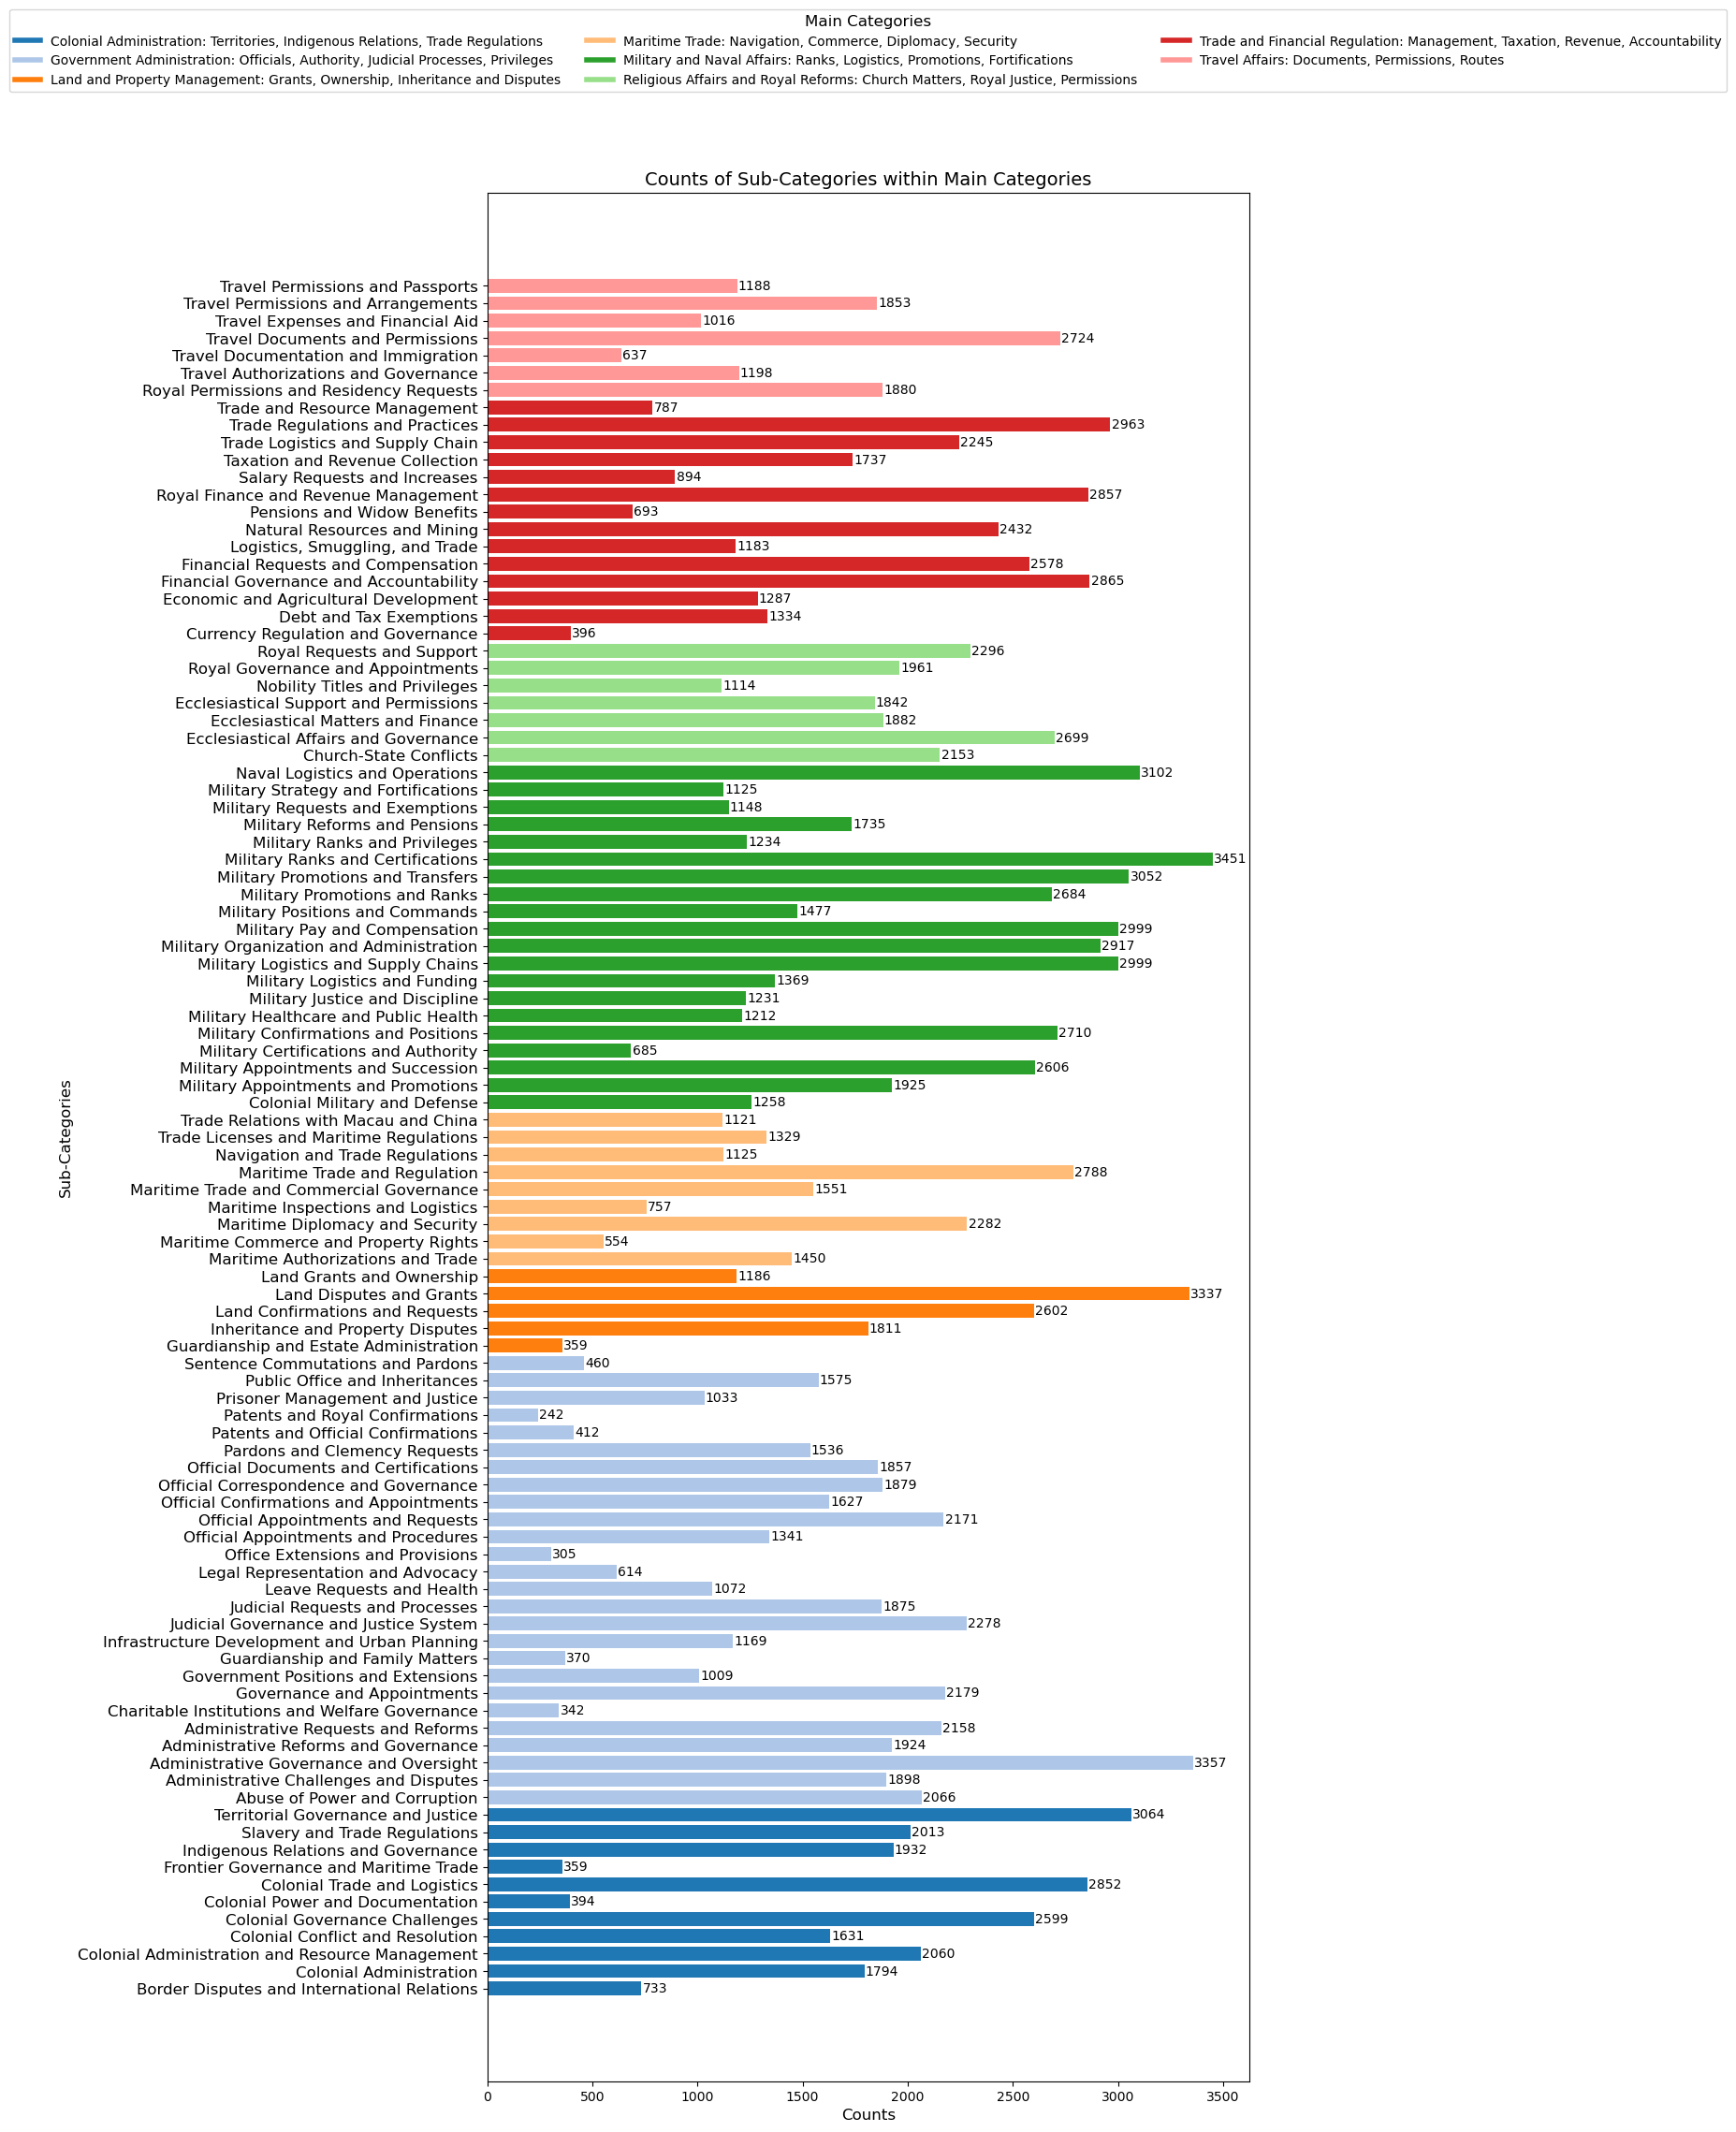

In [34]:
grouped_data = FinalData.groupby('Broad_Category')['Cluster_Label_Topic'].value_counts()

grouped_data = grouped_data.reset_index(name='Counts')

grouped_data.rename(columns={
    'Broad_Category': 'Main_Category', 
    'Cluster_Label_Topic': 'Sub_Category'
}, inplace=True)


grouped_data_sorted = grouped_data.sort_values(by=['Main_Category', 'Sub_Category'])

grouped_data_sorted['Combined_Category'] = grouped_data_sorted['Main_Category'] + " - " + grouped_data_sorted['Sub_Category']

y_labels = grouped_data_sorted['Sub_Category']
x_counts = grouped_data_sorted['Counts']
categories = grouped_data_sorted['Main_Category'].unique()

category_colors = {category: plt.cm.tab20(i) for i, category in enumerate(categories)}

bar_colors = grouped_data_sorted['Main_Category'].map(category_colors)

plt.figure(figsize=(16, 24))  
bars = plt.barh(y_labels, x_counts, color=bar_colors)

for bar, count in zip(bars, x_counts):
    plt.text(
        bar.get_width() + 5,  
        bar.get_y() + bar.get_height() / 2,  
        str(count), 
        va='center',  
        fontsize=10, 
    )

plt.ylabel('Sub-Categories', fontsize=12)
plt.xlabel('Counts', fontsize=12)
plt.title('Counts of Sub-Categories within Main Categories', fontsize=14)

plt.yticks(fontsize=12)

legend_labels = [plt.Line2D([0], [0], color=color, lw=4) for color in category_colors.values()]
plt.legend(
    legend_labels,
    categories,
    title='Main Categories',
    bbox_to_anchor=(0.5, 1.05), 
    loc='lower center',
    ncol=3,  
    fontsize=10,
    title_fontsize=12,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])  

plt.savefig('horizontal_bar_chart.png', dpi=200)

plt.show()


<div style="text-align: center;">
    <h1 style="color: #28A745;">⬆️🎯 <strong>End of Stage-3</strong> 🎉⬆️</h1>
</div>
